# Task #6: Baseline Conversation-Quality Model

In this notebook we build our first (simple) models for measuring quality in
online discussions. We use the CGA-CMV dataset: arguments from Reddit's
r/changemyview, where some conversations stayed polite and some turned rude and uncivil.


## What do we mean by "quality"?

Our team decided that quality should be a
rubric with a few parts:
- Civility: are people being respectful?
- Relevance: are they staying on topic?
- Reasoning: are they making good arguments?
- Constructiveness: are they adding something useful?

This notebook builds the civility idea and at both levels

| Level | The question we ask | Possible answers |
|---|---|---|
| One reply | Is this comment rude enough that a moderator would delete it? | `civil` or `uncivil` |
| Whole conversation | Looking at how it starts, will this conversation stay polite or turn rude? | `civil` or `derailed` |

At both levels the model gives a quality score from 0 to 1: how likely it is
that the reply or conversation is civil, here Higher = better.

### How this baseline fits the full quality model

The other three parts (relevance, reasoning, constructiveness) aren't built yet and a tentative plan for them is in Part C of the doc; our eventual quality model is intended to combine all four parts into an aggregate score. Because the available labels in this dataset measure civility, the quality score in this notebook represents the civility-based baseline, not the final comprehensive quality judgment.

## Where do the labels come from?

We didn't label anything by hand, The dataset tells us whether each conversation
ended with a comment that moderators removed for breaking Rule 2: "Don't be rude
or hostile." So:
- the last comment of a "derailed" conversation is a real example of a rude reply
- the last comment of a "civil" conversation is a real example of a polite reply

## Our plan

For each part, we try a few models.

Part A: Is this reply rude? We try 3 models:
1. Always guess the same answer, No learning at all. This is the score to beat (about 50%).
2. Simple text stats (from Task 4a): length, capital letters, `?`, `!`, links.
3. The words in the comment (TF-IDF): learns which words show up in rude vs. polite comments.

Part B: Will this conversation turn rude? We try 4 models:
1. Always guess the same answer, Again, the score to beat.
2. Conversation shape (from Task 4b): number of comments, number of people, how fast they reply.
3. Rudeness scores: run the Part A model on each comment, then use those scores.
4. Shape + rudeness scores together. This turns out to be the best, so it's our main model.

We also show two extra models just for comparison: the words in the opening
comments (TF-IDF), and shape + upvote scores (which we don't trust, see rule 4 below).

## How we avoid leakage

If a model accidentally sees the answer, it looks great but is useless in real
life, this is the idea of leakage. Our rules to address this are the folllowing

1. Hide the last comment. In a derailed conversation the last comment is the
   rude one, so the conversation model never gets to see it.
2. Use the dataset's own train/val/test split. Every rude conversation has a
   matching polite one about the same post. The official split keeps each matching
   pair together, so the model can't learn the topic from one and use it on the other.
3. Remove features that give away the answer, like counts of deleted comments.
4. Don't trust upvote/downvote scores. They were collected after the
   conversation ended, so they might include downvotes from the fight itself. We
   only show them as a side comparison.
5. Don't let the rudeness scores peek. When we score replies in the training
   data, we use a version of the reply model that never saw that conversation's answer.

We compared models on the val set and only looked at test at the end.
The code is in `artifacts/conversation_quality.py` and the tests are in
`tests/test_conversation_quality.py`.

In [1]:
from pathlib import Path
import sys
import warnings

current = Path.cwd()
repo_root = current if (current / "artifacts").exists() else current.parent
sys.path.insert(0, str(repo_root / "artifacts"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from conversation_quality import (
    CIVIL, DERAILED, UNCIVIL, REPLY_SCORE_COLUMNS, TEXT_FEATURE_COLUMNS,
    load_examples, load_replies, add_reply_scores, structural_columns, paired_accuracy,
    majority_baseline, feature_model, text_model,
)
from evaluation import evaluate_classifier
from standardize_convokit import iter_standardized

path = repo_root / "data" / "local" / "standardized-v1" / "conversations-gone-awry-cmv-corpus.jsonl"


def score(model, X, frame):
    """Label metrics via evaluation.py, plus ranking metrics for the quality score."""
    result = evaluate_classifier(model, X, frame["label"].tolist())
    quality = model.quality_scores(X)
    return result, quality, {
        "accuracy": result.accuracy,
        "macro_f1": result.macro_f1,
        "roc_auc": roc_auc_score(frame["label"] == CIVIL, quality),
        "paired_acc": paired_accuracy(quality, frame["label"].tolist(),
                                      frame["pair_id"].tolist(), frame["conversation_id"].tolist()),
    }

How we measure the models
- Accuracy: what fraction of answers were right, Guessing gets 50%.
- Macro F1: like accuracy, but it punishes a model that only ever guesses one answer
- ROC AUC: if we pick one civil and one non-civil example at random, how often
  does the civil one get the higher quality score? 0.5 = coin flip, 1.0 = perfect.
- Paired accuracy: the same idea, but we only compare each example with its
  matching partner about the same post. This is the fairest test, since the topic
  is the same and only the behavior is different.

---
# Part A: Is this reply rude?

In [2]:
finals, openings = load_replies(path)
print("Labeled final replies:", len(finals), "| unlabeled opening replies:", len(openings))
pd.crosstab(finals["split"], finals["label"], margins=True)

Labeled final replies: 6576 | unlabeled opening replies: 35196


label,civil,uncivil,All
split,,,
test,654,649,1303
train,1987,1976,3963
val,663,647,1310
All,3304,3272,6576


Here are some real replies that moderators removed  (A lot of them aren't obvious
swearing and can be more subtly hostile or condescending).

In [3]:
for text in finals[finals["label"] == UNCIVIL]["text"].sample(6, random_state=1):
    print("•", text[:250].replace("\n", " "))
    print()

• >Who is expecting them to?  The entirety of those who believe that the minimum wage is fine where it is? Otherwise, employers who pay just the minimum wage are essentially wiping their hands of it and saying "We get that you don't have enough money t

• If you don't personally agree, then why do you advocate preventing same-sex couples from enjoying legal marriage?

• >In this context, the responsibility is to provide accurate information if you are interested in the job.  And if you fail to do so, you should be fined. Right?  >You are not engaging in the discussion.  Yes I am.  >You are stating what may be true  

• If you demonstrate you are willing to commit violence on someone without provocation hey aren't responsible for your safety, only their own. If they have legitimate reason to believe that's what it will take, then that's what they're entitled to do. 

• No it isn't.  Loans are based on merit.  Job history, credit, assets.  .... so yeah....  Edit: lol I've done far more r

In [4]:
reply_train, reply_val, reply_test = (finals[finals["split"] == s] for s in ("train", "val", "test"))

reply_models = {
    "Majority class": (majority_baseline().fit(reply_train, reply_train["label"]), lambda d: d),
    "Task 4a text features": (feature_model(TEXT_FEATURE_COLUMNS).fit(reply_train, reply_train["label"]), lambda d: d),
    "TF-IDF text": (text_model().fit(reply_train["text"], reply_train["label"]), lambda d: d["text"]),
}
pd.DataFrame({name: score(m, X(reply_val), reply_val)[2] for name, (m, X) in reply_models.items()}).T.round(3)

,accuracy,macro_f1,roc_auc,paired_acc
Majority class,0.506,0.336,0.500,0.500
Task 4a text features,0.529,0.524,0.541,0.537
TF-IDF text,0.631,0.631,0.679,0.678


The words in the comment (TF-IDF) do best by a lot. The simple text stats
(length, capital letters, `?`, `!`, links) barely beat guessing, so rudeness is
about what people say more than it is  the punctuation. TF-IDF is our reply-level model.

Now the test results (data the model has never seen):

In [5]:
reply_test_scores = {name: score(m, X(reply_test), reply_test) for name, (m, X) in reply_models.items()}
reply_test_table = pd.DataFrame({name: s[2] for name, s in reply_test_scores.items()}).T
reply_test_table.round(3)

,accuracy,macro_f1,roc_auc,paired_acc
Majority class,0.502,0.334,0.500,0.500
Task 4a text features,0.571,0.570,0.578,0.569
TF-IDF text,0.622,0.622,0.664,0.689


In [6]:
reply_result = reply_test_scores["TF-IDF text"][0]
print("Reply TF-IDF — test per-class F1:", {k: round(v, 3) for k, v in reply_result.per_class_f1.items()})
print(pd.DataFrame(reply_result.confusion, index=reply_result.labels, columns=reply_result.labels))

reply_tfidf = reply_models["TF-IDF text"][0].pipeline
vocab = reply_tfidf.named_steps["tfidf"].get_feature_names_out()
weights = reply_tfidf.named_steps["classifier"].coef_[0]   # + = toward 'uncivil'
order = np.argsort(weights)
print("\nToward UNCIVIL:", ", ".join(vocab[order[-25:][::-1]]))
print("\nToward CIVIL:  ", ", ".join(vocab[order[:25]]))

Reply TF-IDF — test per-class F1: {'civil': 0.623, 'uncivil': 0.622}
         civil  uncivil
civil      406      248
uncivil    244      405

Toward UNCIVIL: you, your, no, re, you re, again, and, history, are you, read, not, going to, fact, here, arguments, if you, me, live, absolutely, one, got, yes, you don, stop, because

Toward CIVIL:   but, agree, think, the, be, though, point, find, example, my point, to be, these, probably, into, also, tax, more, could, source, for the, other, so many, agree that, seeing, something


Seems model learned that Rude replies use lots of words aimed at the other
person (you, your, you're, are you, if you) and dismissive words (no, stop,
again, absolutely). Polite replies use softer, more open words (but, agree,
think, though, point, example, source). this makes sense!

---
# Part B: Will this conversation turn rude?

In [7]:
examples = load_examples(path)
pd.crosstab(examples["split"], examples["label"], margins=True)

label,civil,derailed,All
split,,,
test,684,684,1368
train,2053,2053,4106
val,684,684,1368
All,3421,3421,6842


In [8]:
# Leakage rule 2: every matched pair lives entirely inside one split.
split_of = dict(zip(examples["conversation_id"].str.rsplit(":", n=1).str[-1], examples["split"]))
print("Pairs split across train/val/test:",
      sum(split_of[p] != s for p, s in zip(examples["pair_id"], examples["split"])))

Pairs split across train/val/test: 0


Here's what the conversation model is getting to see for one derailed
conversation. The last comment (the rude one) is hidden as said before.

In [9]:
example_id = examples[(examples["split"] == "train") & (examples["label"] == DERAILED)
                      & (examples["n_context"] == 2)]["conversation_id"].iloc[0]
conversation = next(c for c in iter_standardized(path) if c.id == example_id)
ordered = sorted(conversation.utterances, key=lambda u: u.created_at)
for i, u in enumerate(ordered):
    tag = "HIDDEN (outcome)" if i == len(ordered) - 1 else "opening"
    print(f"[{tag}] {u.text_clean[:300]}")
    print("-" * 80)

[opening] If someone has crippling dysphoria over their genitalia, peeing in a way that requires them to hold and view said genitalia is not going to be the preferred method. You also operate under a false premise; standing isn't objectively superior. Outside of speed/convenience and personal hygiene, it offe
--------------------------------------------------------------------------------
[opening] >crippling dysphoria

Sounds like a mental illness to me.

>Standing increases risk of making a mess, after all.

See my other posts in the thread - every 'advantage' sitting offers is easily debunked.
--------------------------------------------------------------------------------
[HIDDEN (outcome)] It's not a mental illness though, as confirmed by the American Psychiatric Association in the DSM-V and every other major psychological association. If they are sayings that it isn't mental illness, how can you?
--------------------------------------------------------------------------------


## What the model looks at

- Conversation shape (from Task 4b): how many comments there are, how many
  people are talking, how fast they reply, and whether two people are going back
  and forth. itt doesn't read the words
- Rudeness scores (from Part A): we run the reply model on every comment
  before the last one and then keep three numbers per conversation, the rudest
  comment, the average one, and the most recent comment before the end

In [10]:
examples = add_reply_scores(examples, finals, openings)
train, val, test = (examples[examples["split"] == s] for s in ("train", "val", "test"))

structural = structural_columns(train, include_votes=False)
with_votes = structural_columns(train, include_votes=True)
reply_cols = list(REPLY_SCORE_COLUMNS)

print(f"Structural ({len(structural)}):", ", ".join(structural))
print(f"\nReply scores ({len(reply_cols)}):", ", ".join(reply_cols))
print(f"\nVote features ({len(with_votes) - len(structural)}):",
      ", ".join(c for c in with_votes if c not in structural))

Structural (18): n_utterances, max_depth, mean_depth, max_branching, depth_ratio, duration_seconds, median_reply_gap, mean_reply_gap, min_reply_gap, max_reply_gap, time_to_first_reply, gap_acceleration, growth_rate_per_hour, n_speakers, top_speaker_share, top_two_speaker_share, self_reply_count, utterances_per_speaker

Reply scores (3): reply_min_civil, reply_mean_civil, reply_last_civil

Vote features (7): min_score, mean_score, n_negative_score, root_score, last_score, score_trend, min_score_position


In [11]:
conversation_models = {
    "Majority class": (majority_baseline(), lambda d: d),
    "Structural": (feature_model(structural), lambda d: d),
    "Reply scores": (feature_model(reply_cols), lambda d: d),
    "Structural + reply scores": (feature_model(structural + reply_cols), lambda d: d),
    "TF-IDF opening text": (text_model(), lambda d: d["context_text"]),
    "Structural + votes (diagnostic)": (feature_model(with_votes), lambda d: d),
}
for model, X in conversation_models.values():
    model.fit(X(train), train["label"])

pd.DataFrame({name: score(m, X(val), val)[2] for name, (m, X) in conversation_models.items()}).T.round(3)

,accuracy,macro_f1,roc_auc,paired_acc
Majority class,0.500,0.333,0.500,0.500
Structural,0.588,0.587,0.626,0.678
Reply scores,0.603,0.603,0.642,0.656
Structural + reply scores,0.628,0.628,0.675,0.696
TF-IDF opening text,0.591,0.591,0.624,0.645
Structural + votes (diagnostic),0.618,0.616,0.656,0.689


Shape and rudeness scores each beat guessing on their own, and using both
together works best. Hpever that makes sense, because they capture different things,
how the conversation is going vs. what people are saying. So
shape + rudeness scores is our main conversation model.

(The upvote version also looks good, but via rule 4, we can't trust it.)

the test results:

In [12]:
conv_test_scores = {name: score(m, X(test), test) for name, (m, X) in conversation_models.items()}
conv_test_table = pd.DataFrame({name: s[2] for name, s in conv_test_scores.items()}).T
conv_test_table.round(3)

,accuracy,macro_f1,roc_auc,paired_acc
Majority class,0.500,0.333,0.500,0.500
Structural,0.596,0.595,0.620,0.655
Reply scores,0.588,0.588,0.620,0.617
Structural + reply scores,0.611,0.611,0.656,0.662
TF-IDF opening text,0.576,0.576,0.605,0.621
Structural + votes (diagnostic),0.602,0.601,0.640,0.690


In [ ]:
headline, headline_quality, _ = conv_test_scores["Structural + reply scores"]
print("Structural + reply scores test per-class F1:", {k: round(v, 3) for k, v in headline.per_class_f1.items()})
print("Confusion matrix (rows = true, cols = predicted):")
print(pd.DataFrame(headline.confusion, index=headline.labels, columns=headline.labels))

Structural + reply scores — test per-class F1: {'civil': 0.614, 'derailed': 0.608}
Confusion matrix (rows = true, cols = predicted):
          civil  derailed
civil       424       260
derailed    272       412


## Charts

Left: how well each model ranks things (ROC AUC) on the test set. The dashed
line is just 50/50 a coin flip, and longer bars are better.
Right: the quality scores our main model gave to civil (blue) vs. derailed
(orange) conversations. The civil ones are shifted higher, but there's a lot of
overlap and so the model is helpful but far from perfect.

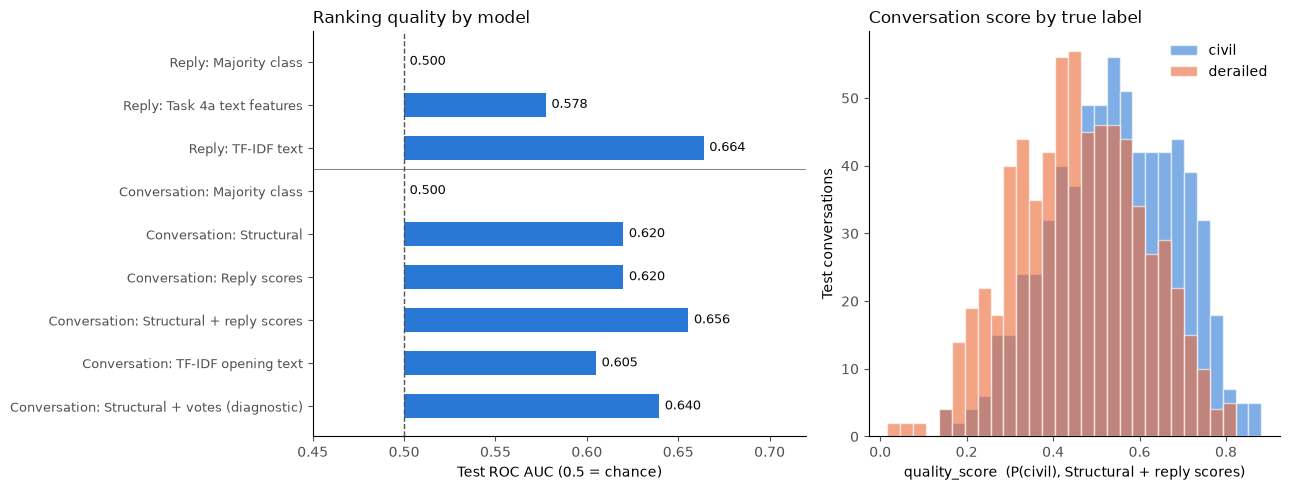

In [14]:
import matplotlib.pyplot as plt

CIVIL_COLOR, DERAILED_COLOR = "#2a78d6", "#eb6834"   # validated categorical slots 1-2
INK, MUTED = "#0b0b0b", "#52514e"

auc_rows = [(f"Reply: {n}", v) for n, v in reply_test_table["roc_auc"].items()] + \
           [(f"Conversation: {n}", v) for n, v in conv_test_table["roc_auc"].items()]
names, values = zip(*auc_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
y = np.arange(len(names))[::-1]
ax1.barh(y, np.array(values) - 0.5, left=0.5, height=0.55, color=CIVIL_COLOR)
for yi, v in zip(y, values):
    ax1.text(v + 0.003, yi, f"{v:.3f}", va="center", color=INK, fontsize=9)
ax1.axvline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax1.axhline(len(names) - len(reply_test_table) - 0.5, color=MUTED, linewidth=0.5)
ax1.set_yticks(y, names, fontsize=9)
ax1.set_xlim(0.45, 0.72)
ax1.set_xlabel("Test ROC AUC (0.5 = chance)")
ax1.set_title("Ranking quality by model", loc="left", color=INK)

q = np.array(headline_quality)
is_civil = (test["label"] == CIVIL).to_numpy()
bins = np.linspace(q.min(), q.max(), 30)
ax2.hist(q[is_civil], bins=bins, alpha=0.6, color=CIVIL_COLOR, label="civil", edgecolor="white", linewidth=1)
ax2.hist(q[~is_civil], bins=bins, alpha=0.6, color=DERAILED_COLOR, label="derailed", edgecolor="white", linewidth=1)
ax2.set_xlabel("quality_score  (P(civil), Structural + reply scores)")
ax2.set_ylabel("Test conversations")
ax2.set_title("Conversation score by true label", loc="left", color=INK)
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
plt.tight_layout()
plt.show()

## What did the main model learn?

Each feature gets a weight. Positive = pushes toward "derailed", negative =
pushes toward "civil". For example, conversations where one person does most of
the talking tend to stay civil, while two people trading replies over a long time
tends to go badly.

In [15]:
headline_model = conversation_models["Structural + reply scores"][0]
assert list(headline_model.pipeline.classes_) == [CIVIL, DERAILED]   # coef sign is toward DERAILED
coefs = pd.Series(headline_model.pipeline.named_steps["classifier"].coef_[0],
                  index=structural + reply_cols).sort_values()
coefs.round(3).to_frame("coef (+ = derailed)")

,coef (+ = derailed)
top_speaker_share,-0.352
reply_last_civil,-0.233
reply_mean_civil,-0.225
utterances_per_speaker,-0.186
mean_reply_gap,-0.181
reply_min_civil,-0.170
max_branching,-0.130
depth_ratio,-0.130
growth_rate_per_hour,-0.077
self_reply_count,-0.016


## Where the model gets it wrong

The civil conversations the model was most sure would turn rude, and the rude ones
it was most sure would stay civil, this is so that we can look at mistakes and  figure out what to
improve next

In [16]:
errors = test.assign(quality_score=headline_quality)[["label", "n_context", "quality_score", "context_text"]]
errors["context_text"] = errors["context_text"].str.slice(0, 200).str.replace("\n", " ")
pd.set_option("display.max_colwidth", 200)

print("Civil threads scored as most likely to derail:")
display(errors[errors["label"] == CIVIL].nsmallest(5, "quality_score"))
print("Derailed threads scored as most likely to stay civil:")
display(errors[errors["label"] == DERAILED].nlargest(5, "quality_score"))

Civil threads scored as most likely to derail:


,label,n_context,quality_score,context_text
4519,civil,2,0.151111,"God(s) doesn't exist for the same reason flying purple elephants don't exist -- namely, they haven't been (yet) proven to exist. This doesn't preclude that one or more gods couldn't ever be proven..."
2874,civil,10,0.156760,">I haven't really seen any serious academic support for Trump's agenda I want to focus on this bit in particular. What you're saying here is ""I've read a lot of arguments against trump, not a sin..."
1833,civil,2,0.157912,Would you agree that being hit with napalm and surviving with extreme burn percentages is not only worse and is more probable that being shot and surviving? no
1011,civil,7,0.165521,"How can your view change on this? It's built on outrage over a specific subset of feminists *tactics* rather than their ideas. For instance, I am a feminist and I promise not to call you a misogyn..."
1976,civil,6,0.166760,"Some people are against Satanism because they see it as a perversion of an existing religion and not a religion of its own. Not because they don't respect their right to believe what they want, b..."


Derailed threads scored as most likely to stay civil:


,label,n_context,quality_score,context_text
3243,derailed,5,0.805166,"What the hell is wrong with you? Referring to a character as ""colored"". What year do you think it is? Is that not politically correct now? I thought it was. Apologies. Figured since People of Col..."
2071,derailed,1,0.798555,"Jill Stein is motivated only by getting attention for herself. There are many kinds of voter fraud. In-person voter identification fraud - that is, I turn up and say I'm not Lt. Fred but someone ..."
5800,derailed,1,0.797908,"Negative feedback is not the same as useful feedback. Positive feedback can motivate a person to improve, and it can uplift a person who is going through a tough time. It can even ignite a passio..."
758,derailed,2,0.793895,"My wife and I have been married for five years, together for ten. We have a four-year old. I earn enough on my own to make a comfortable middle-class living. I'm also completing a graduate degree ..."
697,derailed,1,0.792714,Cows were domesticated and bred solely for the purpose of eating. Dogs and cats were not.


---
# Part C: Our plan for the full quality rubric

Right now only civility has ready-made labels, tentatively this is an idea of how we could do the others without hand-labeling every comment

| Part | Level | Status | How we'd measure it | How we'd check it |
|---|---|---|---|---|
| Civility | reply + conversation | done (this notebook) | moderator removals in CGA-CMV | test set (above) |
| Relevance | reply | planned | compare each reply to the original post using Task 7's embeddings (turning text into numbers so we can measure how similar two pieces of text are) | hand-label ~100 replies as on-topic or off-topic |
| Reasoning | reply | planned | ConvoKit's Winning Arguments dataset, which marks replies that actually changed someone's mind | its own test set |
| Constructiveness | reply | planned | discourse labels from Task 5 (e.g. answer/elaboration = constructive, negative reaction = not) | compare with a small hand-labeled set |

Putting it together: a conversation's overall quality could combine its
civility score with the average of its replies' scores. How much each part should
count is something we'll decide as a team in October.

---
# Summary

What was built: two civility models.
1. A reply-level model that scores how likely one comment is to be rude.
2. A conversation-level model that predicts, from how a conversation starts,
   whether it will turn rude. It uses the conversation's shape plus the reply scores.

Both give a quality score from 0 to 1 (higher = more civil). This covers the
civility part of our rubric, but not persuasiveness or relevance yet (see Part C).

Results on the test set:

| Level | Model | Accuracy | Macro F1 | ROC AUC | Paired acc. |
|---|---|---|---|---|---|
| Reply (1,303) | Always guess one answer | 0.502 | 0.334 | 0.500 | 0.500 |
| Reply | Simple text stats (Task 4a) | 0.571 | 0.570 | 0.578 | 0.569 |
| Reply | Words in the comment (TF-IDF) | 0.622 | 0.622 | 0.664 | 0.689 |
| Conversation (1,368) | Always guess one answer | 0.500 | 0.333 | 0.500 | 0.500 |
| Conversation | Shape only | 0.596 | 0.595 | 0.620 | 0.655 |
| Conversation | Rudeness scores only | 0.588 | 0.588 | 0.620 | 0.617 |
| Conversation | Shape + rudeness scores | 0.611 | 0.611 | 0.656 | 0.662 |
| Conversation | Words in the opening (TF-IDF) | 0.576 | 0.576 | 0.605 | 0.621 |
| Conversation | Shape + upvotes (not trusted) | 0.602 | 0.601 | 0.640 | 0.690 |

Main takeaways:
- Both models beat guessing (about 61–62% vs. 50%) but no tby a lot
- Rudeness shows up in the words, especially words aimed at the other person
  ("you", "your").
- Reply scores make the conversation model better!

Limitations:
- Moderators don't catch every rude comment, and they sometimes remove borderline
  ones, so our labels aren't perfect.
- We only have labels for the last reply of each conversation, so when the reply
  model scores earlier replies, it's really just making an educated guess.
- Very short conversations (only 2 comments) give the model almost nothing to go on.
- The text models partly learn which topics get heated, not just how people
  argue. We should check this for bias later.

Next steps (October):
- Build the relevance part using Task 7's embeddings
- Try the Winning Arguments dataset for reasoning
- Try a fancier model (like a fine-tuned transformer) only if it clearly beats this baseline
- Decide as a team how to combine the rubric scores